**Step 1: Setup**

In [1]:
!nvidia-smi
!pip install tiktoken

Mon Nov 23 18:38:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch
import tiktoken

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
print("using device:", device)

PyTorch version: 2.14.1+cu130
CUDA available: True
using device: cuda


In [3]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-11-23 18:39:01--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.04s   

2026-11-23 18:39:01 (27.8 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [4]:
with open('input.txt', 'r') as f:
    text = f.read()

print("characters:", len(text))
print(text[:1000])

enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode(text)
print("tokens:", len(tokens))
print(tokens[:24])

characters: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in t

**Step 2: Model banana**

In [5]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
from torch.nn import functional as F

# -----------------------------------------------------------------------------

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        assert config.n_head % config.n_kv_head == 0  # GQA: query heads must divide evenly into KV groups
        self.n_head = config.n_head
        self.n_kv_head = config.n_kv_head  # GQA: number of key/value heads
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head
        self.kv_dim = self.n_kv_head * self.head_dim
        # key, query, value projections (GQA: K and V have fewer heads than Q)
        self.c_attn = nn.Linear(config.n_embd, config.n_embd + 2 * self.kv_dim)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # not really a 'bias', more of a mask, but following the OpenAI/HF naming though
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values
        qkv = self.c_attn(x)
        q, k, v = qkv.split([self.n_embd, self.kv_dim, self.kv_dim], dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)     # (B, nh, T, hs)
        k = k.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)  # (B, n_kv, T, hs)
        v = v.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)  # (B, n_kv, T, hs)
        # GQA: each K/V head is shared by a group of (n_head // n_kv_head) query heads
        n_rep = self.n_head // self.n_kv_head
        k = k.repeat_interleave(n_rep, dim=1)  # (B, nh, T, hs)
        v = v.repeat_interleave(n_rep, dim=1)  # (B, nh, T, hs)
        # attention (materializes the large (T,T) matrix for all the queries and keys)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of query heads
    n_kv_head: int = 4 # GQA: number of key/value heads (n_kv_head == n_head -> normal multi-head attention)
    n_embd: int = 768 # embedding dimension

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight

        # init params
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        config_args['n_kv_head'] = config_args['n_head'] # OpenAI GPT-2 uses normal multi-head attention (no GQA)
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

In [6]:
num_return_sequences = 5
max_length = 30

model = GPT.from_pretrained('gpt2')
model.eval()
model.to(device)

enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Hello, I'm a language model,")
tokens = torch.tensor(tokens, dtype=torch.long)
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
x = tokens.to(device)

torch.manual_seed(42)
torch.cuda.manual_seed(42)
while x.size(1) < max_length:
    with torch.no_grad():
        logits, loss = model(x)
        logits = logits[:, -1, :]
        probs = F.softmax(logits, dim=-1)
        topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
        ix = torch.multinomial(topk_probs, 1)
        xcol = torch.gather(topk_indices, -1, ix)
        x = torch.cat((x, xcol), dim=1)

for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(">", decoded)

loading weights from pretrained gpt: gpt2


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

> Hello, I'm a language model, not a program.

So this morning I started studying for the interview in the lab. This was not
> Hello, I'm a language model, and one of the main things that bothers me when they create languages is how easy it becomes to create something that
> Hello, I'm a language model, and I wrote it off on the grounds that a language model would make me more fluent. But I'm not
> Hello, I'm a language model, I really like languages. I like languages because like, they're good. And the way we talk about languages
> Hello, I'm a language model, a language model I'm using for data modelling. All I did was test the results and then I wrote some


In [7]:
enc = tiktoken.get_encoding('gpt2')
with open('input.txt', 'r') as f:
    text = f.read()
text = text[:1000]
tokens = enc.encode(text)

B, T = 4, 32
buf = torch.tensor(tokens[:B*T + 1])
x = buf[:-1].view(B, T).to(device)
y = buf[1:].view(B, T).to(device)

model = GPT(GPTConfig())   # random weights, GQA (n_kv_head=4)
model.to(device)
logits, loss = model(x, y)
print(logits.shape)
print(loss)

torch.Size([4, 32, 50257])
tensor(10.9582, device='cuda:0', grad_fn=<NllLossBackward0>)


**Step 3: Update Model & Training**

In [8]:
from dataclasses import dataclass
import math
import inspect
import torch
import torch.nn as nn
from torch.nn import functional as F

# -----------------------------------------------------------------------------

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        assert config.n_head % config.n_kv_head == 0  # GQA: query heads must divide evenly into KV groups
        self.n_head = config.n_head
        self.n_kv_head = config.n_kv_head  # GQA: number of key/value heads
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head
        self.kv_dim = self.n_kv_head * self.head_dim
        # key, query, value projections (GQA: K and V have fewer heads than Q)
        self.c_attn = nn.Linear(config.n_embd, config.n_embd + 2 * self.kv_dim)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values
        qkv = self.c_attn(x)
        q, k, v = qkv.split([self.n_embd, self.kv_dim, self.kv_dim], dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)     # (B, nh, T, hs)
        k = k.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)  # (B, n_kv, T, hs)
        v = v.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)  # (B, n_kv, T, hs)
        # GQA: each K/V head is shared by a group of (n_head // n_kv_head) query heads
        n_rep = self.n_head // self.n_kv_head
        k = k.repeat_interleave(n_rep, dim=1)  # (B, nh, T, hs)
        v = v.repeat_interleave(n_rep, dim=1)  # (B, nh, T, hs)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of query heads
    n_kv_head: int = 4 # GQA: number of key/value heads (n_kv_head == n_head -> normal multi-head attention)
    n_embd: int = 768 # embedding dimension

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight

        # init params
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        config_args['n_kv_head'] = config_args['n_head'] # OpenAI GPT-2 uses normal multi-head attention (no GQA)
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

    def configure_optimizers(self, weight_decay, learning_rate, device_type):
        # start with all of the candidate parameters (that require grad)
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decayed, otherwise no.
        # i.e. all weight tensors in matmuls + embeddings decay, all biases and layernorms don't.
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params': decay_params, 'weight_decay': weight_decay},
            {'params': nodecay_params, 'weight_decay': 0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params = sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # Create AdamW optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == "cuda"
        print(f"using fused AdamW: {use_fused}")
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)
        return optimizer

In [9]:
import time
import math
import tiktoken
import torch
from torch.nn import functional as F

# -----------------------------------------------------------------------------
# DataLoaderLite (video: "data loader lite") + train/val split

class DataLoaderLite:
    def __init__(self, B, T, split):
        self.B = B
        self.T = T
        assert split in {'train', 'val'}

        # at init load tokens from disk and store them in memory
        with open('input.txt', 'r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        n = int(0.9 * len(tokens))  # first 90% train, last 10% val
        tokens = tokens[:n] if split == 'train' else tokens[n:]
        self.tokens = torch.tensor(tokens)
        print(f"[{split}] loaded {len(self.tokens)} tokens")
        print(f"[{split}] 1 epoch = {len(self.tokens) // (B * T)} batches")
        self.reset()

    def reset(self):
        # state
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]
        x = (buf[:-1]).view(B, T) # inputs
        y = (buf[1:]).view(B, T) # targets
        # advance the position in the tensor
        self.current_position += B * T
        # if loading the next batch would be out of bounds, reset
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

# -----------------------------------------------------------------------------
# device + seeds

device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"
print(f"using device: {device}")
device_type = "cuda" if device.startswith("cuda") else "cpu"

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

enc = tiktoken.get_encoding('gpt2')

# mixed precision: video uses bfloat16 (A100). The T4 GPU does not support bfloat16,
# so there we use float16 + gradient scaler (the alternative explained in the video).
use_bf16 = device_type == "cuda" and torch.cuda.get_device_capability()[0] >= 8
use_fp16 = device_type == "cuda" and not use_bf16
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
print(f"mixed precision: {'bfloat16' if use_bf16 else ('float16 + GradScaler' if use_fp16 else 'off (fp32)')}")
scaler = torch.amp.GradScaler('cuda', enabled=use_fp16)

# -----------------------------------------------------------------------------
# batch size + gradient accumulation (scaled down from video's 524288 for Tiny Shakespeare)

total_batch_size = 16384 # tokens per optimizer step (2**14)
B = 8 # micro batch size
T = 512 # sequence length
assert total_batch_size % (B * T) == 0, "make sure total_batch_size is divisible by B * T"
grad_accum_steps = total_batch_size // (B * T)
print(f"total desired batch size: {total_batch_size}")
print(f"=> calculated gradient accumulation steps: {grad_accum_steps}")

train_loader = DataLoaderLite(B=B, T=T, split="train")
val_loader = DataLoaderLite(B=B, T=T, split="val")

torch.set_float32_matmul_precision('high')

# create model
model = GPT(GPTConfig(vocab_size=50304)) # "nice number" vocab size, as in the video
model.to(device)
use_compile = False # video: torch.compile interferes with HellaSwag eval and Generation
if use_compile:
    model = torch.compile(model)
print(f"number of parameters: {sum(p.numel() for p in model.parameters()):,}")

# learning rate schedule: linear warmup + cosine decay (from GPT-3 paper)
max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 25
max_steps = 250

def get_lr(it):
    # 1) linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    # 2) if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    # 3) in between, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)

# optimize!
optimizer = model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4, device_type=device_type)

train_losses, val_losses = [], []
for step in range(max_steps):
    t0 = time.time()
    last_step = (step == max_steps - 1)

    # once in a while evaluate our validation loss
    if step % 25 == 0 or last_step:
        model.eval()
        val_loader.reset()
        with torch.no_grad():
            val_loss_accum = 0.0
            val_loss_steps = 8
            for _ in range(val_loss_steps):
                x, y = val_loader.next_batch()
                x, y = x.to(device), y.to(device)
                with torch.autocast(device_type=device_type, dtype=amp_dtype, enabled=device_type == "cuda"):
                    logits, loss = model(x, y)
                loss = loss / val_loss_steps
                val_loss_accum += loss.detach()
        print(f"validation loss: {val_loss_accum.item():.4f}")
        val_losses.append((step, val_loss_accum.item()))

    # once in a while generate from the model (except step 0, which is noise)
    if (step > 0 and step % 50 == 0) or last_step:
        model.eval()
        num_return_sequences = 4
        max_length = 32
        tokens = enc.encode("ROMEO:")
        tokens = torch.tensor(tokens, dtype=torch.long)
        tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
        xgen = tokens.to(device)
        sample_rng = torch.Generator(device=device)
        sample_rng.manual_seed(42)
        while xgen.size(1) < max_length:
            # forward the model to get the logits
            with torch.no_grad():
                with torch.autocast(device_type=device_type, dtype=amp_dtype, enabled=device_type == "cuda"):
                    logits, loss = model(xgen) # (B, T, vocab_size)
                # take the logits at the last position
                logits = logits[:, -1, :] # (B, vocab_size)
                # get the probabilities
                probs = F.softmax(logits.float(), dim=-1)
                # do top-k sampling of 50 (huggingface pipeline default)
                # topk_probs here becomes (5, 50), topk_indices is (5, 50)
                topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
                # select a token from the top-k probabilities
                # note: multinomial does not demand the input to sum to 1
                ix = torch.multinomial(topk_probs, 1, generator=sample_rng) # (B, 1)
                # gather the corresponding indices
                xcol = torch.gather(topk_indices, -1, ix) # (B, 1)
                # append to the sequence
                xgen = torch.cat((xgen, xcol), dim=1)
        # print the generated text
        for i in range(num_return_sequences):
            tokens = xgen[i, :max_length].tolist()
            decoded = enc.decode(tokens)
            print(f"sample {i}: {decoded!r}")

    # do one step of the optimization
    model.train()
    optimizer.zero_grad()
    loss_accum = 0.0
    for micro_step in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device_type, dtype=amp_dtype, enabled=device_type == "cuda"):
            logits, loss = model(x, y)
        # we have to scale the loss to account for gradient accumulation,
        # because the gradients just add on each successive backward().
        # addition of gradients corresponds to a SUM in the objective, but
        # instead of a SUM we want MEAN. Scale the loss here so it comes out right
        loss = loss / grad_accum_steps
        loss_accum += loss.detach()
        scaler.scale(loss).backward()
    scaler.unscale_(optimizer) # (fp16 only) un-scale the grads before clipping
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    scaler.step(optimizer)
    scaler.update()
    if device_type == "cuda":
        torch.cuda.synchronize() # wait for the GPU to finish work
    t1 = time.time()
    dt = t1 - t0 # time difference in seconds
    tokens_processed = train_loader.B * train_loader.T * grad_accum_steps
    tokens_per_sec = tokens_processed / dt
    train_losses.append((step, loss_accum.item()))
    print(f"step {step:4d} | loss: {loss_accum.item():.6f} | lr {lr:.4e} | norm: {norm:.4f} | dt: {dt*1000:.2f}ms | tok/sec: {tokens_per_sec:.2f}")

using device: cuda
mixed precision: float16 + GradScaler
total desired batch size: 16384
=> calculated gradient accumulation steps: 4
[train] loaded 304222 tokens
[train] 1 epoch = 74 batches
[val] loaded 33803 tokens
[val] 1 epoch = 8 batches
number of parameters: 115,026,432
num decayed parameter tensors: 50, with 114,917,376 parameters
num non-decayed parameter tensors: 98, with 109,056 parameters
using fused AdamW: True
validation loss: 10.9517
step    0 | loss: 10.956310 | lr 2.4000e-05 | norm: 28.0832 | dt: 1924.49ms | tok/sec: 8513.41
step    1 | loss: 9.587566 | lr 4.8000e-05 | norm: 14.2419 | dt: 798.24ms | tok/sec: 20525.19
step    2 | loss: 9.328541 | lr 7.2000e-05 | norm: 13.8869 | dt: 810.89ms | tok/sec: 20204.89
step    3 | loss: 9.676320 | lr 9.6000e-05 | norm: 11.3540 | dt: 808.60ms | tok/sec: 20262.25
step    4 | loss: 9.168201 | lr 1.2000e-04 | norm: 5.4982 | dt: 797.40ms | tok/sec: 20546.76
step    5 | loss: 9.000605 | lr 1.4400e-04 | norm: 2.7336 | dt: 798.05ms | to

**Step 4: Results tayyar karna**

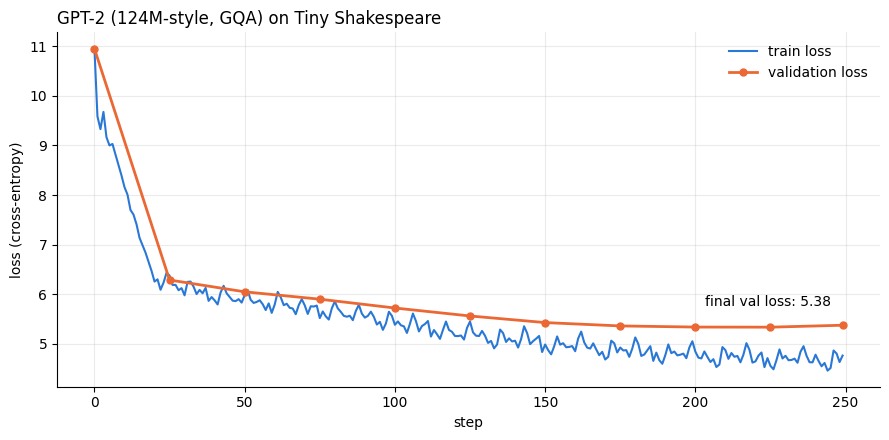

In [10]:
import matplotlib.pyplot as plt

ts, tl = zip(*train_losses)
vs, vl = zip(*val_losses)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ts, tl, color='#2a78d6', linewidth=1.5, label='train loss')
ax.plot(vs, vl, color='#eb6834', linewidth=2, marker='o', markersize=5, label='validation loss')
ax.set_xlabel('step')
ax.set_ylabel('loss (cross-entropy)')
ax.set_title('GPT-2 (124M-style, GQA) on Tiny Shakespeare', loc='left')
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
ax.annotate(f'final val loss: {vl[-1]:.2f}', (vs[-1], vl[-1]),
            textcoords='offset points', xytext=(-8, 14), ha='right')
plt.tight_layout()
plt.savefig('loss_curve.png', dpi=150)
plt.show()

In [11]:
model.eval()
prompts = ["ROMEO:", "JULIET:", "First Citizen:"]
max_new_tokens = 150
sample_rng = torch.Generator(device=device)
sample_rng.manual_seed(42)

for prompt in prompts:
    tokens = torch.tensor(enc.encode(prompt), dtype=torch.long).unsqueeze(0).to(device)
    xgen = tokens
    while xgen.size(1) < tokens.size(1) + max_new_tokens:
        with torch.no_grad():
            with torch.autocast(device_type=device_type, dtype=amp_dtype, enabled=device_type == "cuda"):
                logits, loss = model(xgen)
            logits = logits[:, -1, :]
            probs = F.softmax(logits.float(), dim=-1)
            topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
            ix = torch.multinomial(topk_probs, 1, generator=sample_rng)
            xcol = torch.gather(topk_indices, -1, ix)
            xgen = torch.cat((xgen, xcol), dim=1)
    print("=" * 60)
    print(enc.decode(xgen[0].tolist()))

ROMEO:
And now I do a father of to them with your lord- Murd HEN ELan not a son, as your soul.
CENENRYANUS:
ThINI will know not my lords, that with your lord; in the day!

FIO: for your love'd a love my time with your blood?
DANUS:
I are well's
N Senator:
As I,
As she may have been all
We can go shall not with the head?
Of our hands of the dere a father; a brother, let me,
For this time to bear your gracious honour;
And not
QUEENES:
CAMANUS:
And
JULIET:
DUCHIO:
HENINA:
BUENI must now, so more, for their
KING RICHARDBERIO:
To be in this:
I am thy heart.
Firsttis a poor

KINGINGS:
To the lady.
You would it:
Or it, in me, that, come and you know you, to.



What hath we will not?

O that not you, I were he!
A:
My brother-areULIET: he?


If I have not.

Thy.

CORI come I speak thou'st

IUS:




COR
First Citizen:
And this dost:
That I my mother! how, but not, to go in God's the mother is; I was to you would not me.




What he may


KINGUMYORD:
FUKE IV:
We are not be not, you you can know 

**Results Summary**

- Validation loss: 10.95 → 5.37 in 250 steps (best: 5.33 at step 225), ~4.5 min on a T4 at ~16K tokens/sec
- Validation loss decreased steadily until step 225, then rose slightly at the final evaluation (5.33 → 5.37). With train loss (~4.7) well below validation loss and ~13.5 epochs over the data, the model was starting to overfit; stopping around step 225 would have been optimal
- The model learned Shakespeare's format: character names followed by a colon, short dialogue lines, and archaic words ("thou", "thy", "my lord")
- Limitations: grammar is still weak and some character names are invented, which is expected for a 115M-parameter model trained on only ~300K tokens